<a href="https://colab.research.google.com/github/EddiesEdit/3MTT-Knowledge-Showcase/blob/main/Knowledge_showcase_for_June_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# SmartCart AI: A Cross-Sell Recommender System Using Instacart Shopping Behavior

## Notebook Description:

In this project, we build a robust AI-driven Cross-Sell Recommender System using the Instacart Market Basket Analysis dataset.

The goal is to learn what products are frequently bought together and recommend relevant items to shoppers — just like Amazon or Jumia’s “Frequently Bought Together” feature.

We explore user purchase behavior, perform data preprocessing, generate association rules, and finally develop a user-friendly Streamlit app that offers real-time cross-sell suggestions.

Key Steps:

* Data Exploration & Merging

* Transaction Matrix Creation

* Market Basket Analysis (Apriori / FP-Growth)

* Product Co-occurrence Insights

* Streamlit App Development for real-time recommendation

🎯 Business Value: Boost basket size and customer satisfaction through targeted product recommendations.


In [2]:
# from google.colab import files
# files.upload()  # Choose your kaggle.json file when prompted


In [1]:
import os
from zipfile import ZipFile

# Upload your kaggle.json manually in Colab or your local env
# For Colab:
from google.colab import files
files.upload()

# Create Kaggle folder and move the API key there
os.makedirs("/root/.kaggle", exist_ok=True)
os.rename("kaggle.json", "/root/.kaggle/kaggle.json")

# Set permissions
os.chmod("/root/.kaggle/kaggle.json", 600)


Saving kaggle.json to kaggle.json


In [2]:
!kaggle datasets download -d psparks/instacart-market-basket-analysis
!unzip instacart-market-basket-analysis.zip -d instacart_data

Dataset URL: https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis
License(s): CC0-1.0
 59% 117M/197M [00:00<00:00, 1.21GB/s]
100% 197M/197M [00:00<00:00, 732MB/s] 
Archive:  instacart-market-basket-analysis.zip
  inflating: instacart_data/aisles.csv  
  inflating: instacart_data/departments.csv  
  inflating: instacart_data/order_products__prior.csv  
  inflating: instacart_data/order_products__train.csv  
  inflating: instacart_data/orders.csv  
  inflating: instacart_data/products.csv  


### Import All Required Libraries

In [3]:
# Basic utilities
import os
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Recommender modeling
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Warnings
import warnings
warnings.filterwarnings("ignore")

from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder


### Load All Dataset Files into Pandas

In [4]:
# Path to extracted data
data_path = "instacart_data/"

# Load CSV files
aisles = pd.read_csv(os.path.join(data_path, "aisles.csv"))
departments = pd.read_csv(os.path.join(data_path, "departments.csv"))
products = pd.read_csv(os.path.join(data_path, "products.csv"))
orders = pd.read_csv(os.path.join(data_path, "orders.csv"))
order_products_prior = pd.read_csv(os.path.join(data_path, "order_products__prior.csv"))
order_products_train = pd.read_csv(os.path.join(data_path, "order_products__train.csv"))


In [5]:
print("📦 aisles:", aisles.shape)
print("📦 departments:", departments.shape)
print("📦 products:", products.shape)
print("📦 orders:", orders.shape)
print("📦 order_products_prior:", order_products_prior.shape)
print("📦 order_products_train:", order_products_train.shape)

# Preview one file
products.head()


📦 aisles: (134, 2)
📦 departments: (21, 2)
📦 products: (49688, 4)
📦 orders: (3421083, 7)
📦 order_products_prior: (32434489, 4)
📦 order_products_train: (1384617, 4)


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [6]:
products

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13
...,...,...,...,...
49683,49684,"Vodka, Triple Distilled, Twist of Vanilla",124,5
49684,49685,En Croute Roast Hazelnut Cranberry,42,1
49685,49686,Artisan Baguette,112,3
49686,49687,Smartblend Healthy Metabolism Dry Cat Food,41,8


In [7]:
aisles

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation
...,...,...
129,130,hot cereal pancake mixes
130,131,dry pasta
131,132,beauty
132,133,muscles joints pain relief


In [8]:
departments

,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol
5,6,international
6,7,beverages
7,8,pets
8,9,dry goods pasta
9,10,bulk


In [9]:
orders

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0
...,...,...,...,...,...,...,...
3421078,2266710,206209,prior,10,5,18,29.0
3421079,1854736,206209,prior,11,4,10,30.0
3421080,626363,206209,prior,12,1,12,18.0
3421081,2977660,206209,prior,13,1,12,7.0


In [10]:
products.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [11]:
order_products_prior

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0
...,...,...,...,...
32434484,3421083,39678,6,1
32434485,3421083,11352,7,0
32434486,3421083,4600,8,0
32434487,3421083,24852,9,1


In [13]:
order_products_train.head()

,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


### MERGE DATASETS TO CREATE PRODUCT METADATA

We want a complete product catalog that has the following columns

product_id, product_name, aisle, department

the only way to get that is merging our dataset through the products dataset.

In [13]:
# Merge products with aisles
product_data = pd.merge(products, aisles, on="aisle_id", how="left")

# Merge the result with departments
product_data = pd.merge(product_data, departments, on="department_id", how="left")

# Preview
product_data


,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry
...,...,...,...,...,...,...
49683,49684,"Vodka, Triple Distilled, Twist of Vanilla",124,5,spirits,alcohol
49684,49685,En Croute Roast Hazelnut Cranberry,42,1,frozen vegan vegetarian,frozen
49685,49686,Artisan Baguette,112,3,bread,bakery
49686,49687,Smartblend Healthy Metabolism Dry Cat Food,41,8,cat food care,pets


### Joining Prior Orders with Product Metadata
This will help us analyze co-purchase patterns and prepare for building the recommender system

> i want to understand what products were bought together in the prior orders so we can:
Analyze which products frequently co-occur
Find patterns for cross-selling
Generate recommendations

## Merge for Full Prior Order History

In [14]:
#Join order_products_prior with products metadata
prior_merged = pd.merge(order_products_prior, product_data, on='product_id', how='left')

#Add order context (user_id, order_number, etc.)
prior_merged = pd.merge(prior_merged, orders, on='order_id', how='left')

# View the result
prior_merged


,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,aisle,department,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2,33120,1,1,Organic Egg Whites,86,16,eggs,dairy eggs,202279,prior,3,5,9,8.0
1,2,28985,2,1,Michigan Organic Kale,83,4,fresh vegetables,produce,202279,prior,3,5,9,8.0
2,2,9327,3,0,Garlic Powder,104,13,spices seasonings,pantry,202279,prior,3,5,9,8.0
3,2,45918,4,1,Coconut Butter,19,13,oils vinegars,pantry,202279,prior,3,5,9,8.0
4,2,30035,5,0,Natural Sweetener,17,13,baking ingredients,pantry,202279,prior,3,5,9,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32434484,3421083,39678,6,1,Free & Clear Natural Dishwasher Detergent,74,17,dish detergents,household,25247,prior,24,2,6,21.0
32434485,3421083,11352,7,0,Organic Mini Sandwich Crackers Peanut Butter,78,19,crackers,snacks,25247,prior,24,2,6,21.0
32434486,3421083,4600,8,0,All Natural French Toast Sticks,52,1,frozen breakfast,frozen,25247,prior,24,2,6,21.0
32434487,3421083,24852,9,1,Banana,24,4,fresh fruits,produce,25247,prior,24,2,6,21.0


## Preview Co-Purchases

In [15]:
# Top 10 most frequently purchased products
prior_merged['product_name'].value_counts().head(10)


,count
product_name,
Banana,472565
Bag of Organic Bananas,379450
Organic Strawberries,264683
Organic Baby Spinach,241921
Organic Hass Avocado,213584
Organic Avocado,176815
Large Lemon,152657
Strawberries,142951
Limes,140627


## top co-purchased departments

In [16]:
prior_merged.groupby('department')['product_id'].count().sort_values(ascending=False).head(10)


,product_id
department,
produce,9479291
dairy eggs,5414016
snacks,2887550
beverages,2690129
frozen,2236432
pantry,1875577
bakery,1176787
canned goods,1068058
deli,1051249


In [18]:
grouped = prior_merged.groupby('department')['product_name'].unique()


In [19]:
grouped.head()

,product_name
department,
alcohol,"[Light, Handmade Vodka From Austin, Texas, Noi..."
babies,[Stage 2 Green Bean Pear Greek Yogurt Baby Foo...
bakery,"[Organic Ezekiel 49 Bread Cinnamon Raisin, Pla..."
beverages,"[Original Orange Juice, Sugarfree Energy Drink..."
breakfast,"[Oats & Chocolate Chewy Bars, Kellogg's Nutri-..."


In [20]:
grouped_df = grouped.reset_index()
grouped_df.columns = ['Department', 'Products']
grouped_df.head()

,Department,Products
0,alcohol,"[Light, Handmade Vodka From Austin, Texas, Noi..."
1,babies,[Stage 2 Green Bean Pear Greek Yogurt Baby Foo...
2,bakery,"[Organic Ezekiel 49 Bread Cinnamon Raisin, Pla..."
3,beverages,"[Original Orange Juice, Sugarfree Energy Drink..."
4,breakfast,"[Oats & Chocolate Chewy Bars, Kellogg's Nutri-..."


## Creating a Transaction Matrix

Create a user-product transaction matrix (a.k.a. basket format) where:

Rows = individual orders (or users)

Columns = products

Values = 1 (if purchased), 0 (if not)

This binary format is required for algorithms like Apriori and FP-Growth, which find frequent itemsets and association rules.

In [21]:
# Since the full dataset is massive, let’s work with a sample
# Use only 10,000 orders to reduce memory usage
sample_orders = prior_merged[prior_merged['order_id'].isin(
    prior_merged['order_id'].drop_duplicates().sample(5000, random_state=42)
)]


### Create the Basket Format (Pivot Table)

In [22]:
# Create the transaction matrix: order_id × product_name
basket = (sample_orders
          .groupby(['order_id', 'product_name'])['product_name']
          .count()
          .unstack()
          .fillna(0)
          .applymap(lambda x: 1 if x > 0 else 0))

basket.head()

product_name,#2 Coffee Filters,0 Calorie Acai Raspberry Water Beverage,0 Calorie Fuji Apple Pear Water Beverage,0 Calorie Strawberry Dragonfruit Water Beverage,0% Fat Free Organic Milk,0% Fat Organic Greek Vanilla Yogurt,0% Fat Strawberry Greek Yogurt,0% Fat Superfruits Greek Yogurt,0% Greek Strained Yogurt,"0% Greek, Blueberry on the Bottom Yogurt",...,of Hanover 100 Calorie Pretzels Mini,smart Blend Chicken & Rice Formula Dry Dog Food,smartwater® Electrolyte Enhanced Water,vitaminwater® XXX Acai Blueberry Pomegranate,with Color Safe Brightener Power Paks 2in1 Stain Fighter,with Crispy Almonds Cereal,with Olive Oil Mayonnaise,with Xylitol Island Berry Lime 18 Sticks Sugar Free Gum,with Xylitol Unwrapped Spearmint 50 Sticks Sugar Free Gum,with a Splash of Pineapple Coconut Water
order_id,,,,,,,,,,,,,,,,,,,,,
1005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1229,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1599,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3144,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5803,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:

basket["0 Calorie Fuji Apple Pear Water Beverage"].value_counts()

,count
0 Calorie Fuji Apple Pear Water Beverage,
0,4999
1,1


In [23]:
basket["with Xylitol Cinnamon 18 Sticks Sugar Free Gum"].value_counts()

KeyError: 'with Xylitol Cinnamon 18 Sticks Sugar Free Gum'

In [ ]:
#to save this to my google drive
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
basket.to_csv('/content/drive/MyDrive/Colab Notebooks/3mtt-AI ML/3mtt-AIML-MINI-PROJECT/basket_transactions.csv', index=False)


Now let's find frequent itemsets with a minimum support of 1%

In [26]:
# Find frequent itemsets
frequent_itemsets = fpgrowth(basket, min_support=0.01, use_colnames=True)

# Sort and preview
frequent_itemsets.sort_values(by='support', ascending=False).head()


KeyboardInterrupt: 


📌 Why I Switched from FP-Growth to Apriori
Initially, I intended to use the FP-Growth algorithm for market basket analysis due to its performance advantages on large datasets. However, after upgrading to Colab Pro, I still encountered memory crashes when running FP-Growth on the full dataset of over 3 million orders from Instacart.

To ensure a smooth and efficient learning experience for both myself and notebook viewers, I decided to:

* Reduce the dataset size to 5,000 randomly selected orders.

* Switch to the Apriori algorithm, which is better suited for smaller datasets and more memory-friendly in resource-constrained environments like Colab.

Though Apriori is computationally slower than FP-Growth on large datasets, it provides the same core functionality — discovering frequent itemsets and generating association rules for building a cross-sell product recommender system.

This approach maintains the integrity of the analysis while making it more accessible for educational and demonstration purposes.

In [25]:
pip install mlxtend

In [26]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules


## Run the Apriori Algorithm
Use a minimum support threshold (e.g., 0.01 = 1% of transactions):

In [27]:
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)

# View frequent product combinations
frequent_itemsets.sort_values(by='support', ascending=False).head()

# Generate Association Rules

rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Strongest product association rules
rules.sort_values(by='lift', ascending=False).head()


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
4,(Bag of Organic Bananas),(Organic Raspberries),0.1160,0.0456,0.0146,0.125862,2.760133,1.0,0.00931,1.091819,0.721379,0.099320,0.084097,0.223019
5,(Organic Raspberries),(Bag of Organic Bananas),0.0456,0.1160,0.0146,0.320175,2.760133,1.0,0.00931,1.300335,0.668167,0.099320,0.230968,0.223019
29,(Organic Raspberries),(Organic Strawberries),0.0456,0.0864,0.0108,0.236842,2.741228,1.0,0.00686,1.197131,0.665549,0.089109,0.164670,0.180921
28,(Organic Strawberries),(Organic Raspberries),0.0864,0.0456,0.0108,0.125000,2.741228,1.0,0.00686,1.090743,0.695271,0.089109,0.083194,0.180921
16,(Banana),(Organic Fuji Apple),0.1476,0.0290,0.0104,0.070461,2.429679,1.0,0.00612,1.044603,0.690313,0.062575,0.042699,0.214541


In [29]:
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Organic Baby Spinach),(Bag of Organic Bananas),0.0718,0.1160,0.0144,0.200557,1.728941,1.0,0.006071,1.105770,0.454224,0.083045,0.095653,0.162348
1,(Bag of Organic Bananas),(Organic Baby Spinach),0.1160,0.0718,0.0144,0.124138,1.728941,1.0,0.006071,1.059756,0.476936,0.083045,0.056386,0.162348
2,(Bag of Organic Bananas),(Organic Hass Avocado),0.1160,0.0724,0.0178,0.153448,2.119451,1.0,0.009402,1.095739,0.597488,0.104338,0.087374,0.199652
3,(Organic Hass Avocado),(Bag of Organic Bananas),0.0724,0.1160,0.0178,0.245856,2.119451,1.0,0.009402,1.172190,0.569405,0.104338,0.146896,0.199652
4,(Bag of Organic Bananas),(Organic Raspberries),0.1160,0.0456,0.0146,0.125862,2.760133,1.0,0.009310,1.091819,0.721379,0.099320,0.084097,0.223019
5,(Organic Raspberries),(Bag of Organic Bananas),0.0456,0.1160,0.0146,0.320175,2.760133,1.0,0.009310,1.300335,0.668167,0.099320,0.230968,0.223019
6,(Bag of Organic Bananas),(Organic Strawberries),0.1160,0.0864,0.0184,0.158621,1.835888,1.0,0.008378,1.085836,0.515050,0.100000,0.079051,0.185792
7,(Organic Strawberries),(Bag of Organic Bananas),0.0864,0.1160,0.0184,0.212963,1.835888,1.0,0.008378,1.123200,0.498363,0.100000,0.109687,0.185792
8,(Banana),(Large Lemon),0.1476,0.0480,0.0142,0.096206,2.004291,1.0,0.007115,1.053337,0.587835,0.078280,0.050637,0.196020
9,(Large Lemon),(Banana),0.0480,0.1476,0.0142,0.295833,2.004291,1.0,0.007115,1.210509,0.526334,0.078280,0.173901,0.196020


## ✅ Key Columns Explained
Column	Meaning	Simple Explanation

antecedents	Left side of rule (X)	What they already bought

consequents	Right side of rule (Y)	What we recommend

antecedent support	% of orders with X	How common X is

consequent support	% of orders with Y	How common Y is

support	% of orders with both X and Y	How often X and Y are bought together

confidence	P(Y	X) = how often Y is bought after X

lift	How much more likely Y is bought given X	>1 = good association

leverage	Difference between observed & expected co-occurrence	Measures added value of the combo

conviction	How dependent Y is on X (like confidence, but different math)	Higher is better

jaccard	Similarity of X and Y in transactions	Between 0 and 1

certainty	Strength of certainty in rule	Higher = more reliable

kulczynski	Balance between P(Y	X) and P(X

## Top Rules Bar Chart

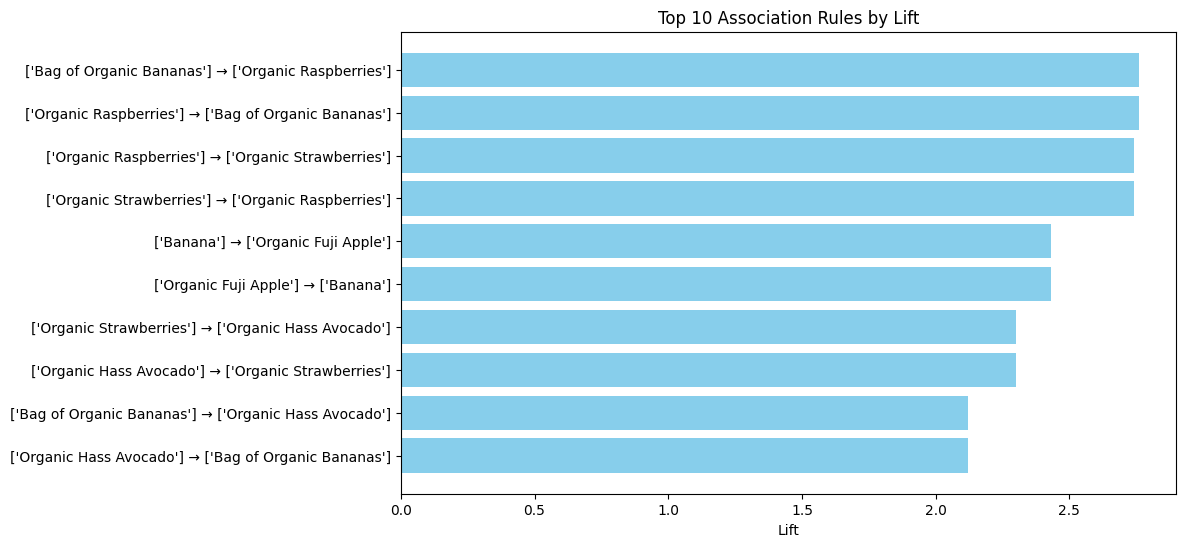

In [28]:
import matplotlib.pyplot as plt

top_rules = rules.sort_values(by='lift', ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(range(len(top_rules)), top_rules['lift'], color='skyblue')
plt.yticks(range(len(top_rules)), [f"{list(a)} → {list(c)}" for a, c in zip(top_rules['antecedents'], top_rules['consequents'])])
plt.xlabel("Lift")
plt.title("Top 10 Association Rules by Lift")
plt.gca().invert_yaxis()
plt.show()


## Scatter Plot: Support vs Confidence

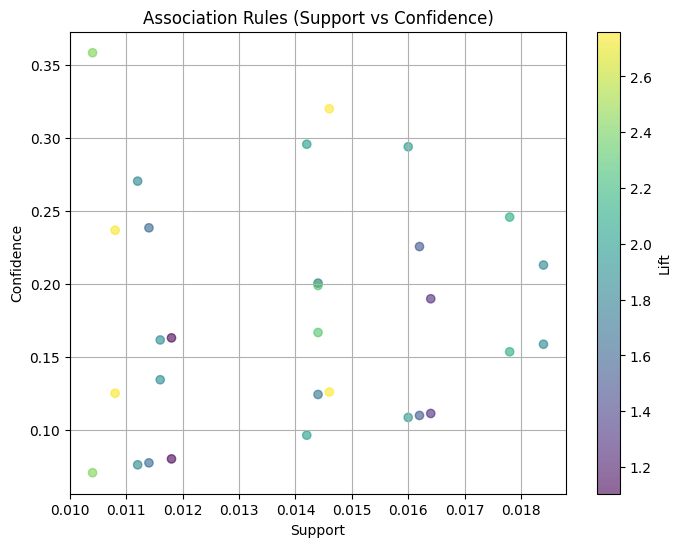

In [29]:
plt.figure(figsize=(8,6))
plt.scatter(rules['support'], rules['confidence'], alpha=0.6, c=rules['lift'], cmap='viridis')
plt.colorbar(label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Association Rules (Support vs Confidence)')
plt.grid(True)
plt.show()


## Filter the rule with best param__

In [33]:
filtered_rules = rules[
    (rules['lift'] >= 2) &
    (rules['confidence'] >= 0.2) &
    (rules['support'] >= 0.01)
].sort_values(by='lift', ascending=False)
filtered_rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
5,(Organic Raspberries),(Bag of Organic Bananas),0.0456,0.1160,0.0146,0.320175,2.760133,1.0,0.009310,1.300335,0.668167,0.099320,0.230968,0.223019
29,(Organic Raspberries),(Organic Strawberries),0.0456,0.0864,0.0108,0.236842,2.741228,1.0,0.006860,1.197131,0.665549,0.089109,0.164670,0.180921
17,(Organic Fuji Apple),(Banana),0.0290,0.1476,0.0104,0.358621,2.429679,1.0,0.006120,1.329011,0.605997,0.062575,0.247561,0.214541
3,(Organic Hass Avocado),(Bag of Organic Bananas),0.0724,0.1160,0.0178,0.245856,2.119451,1.0,0.009402,1.172190,0.569405,0.104338,0.146896,0.199652
9,(Large Lemon),(Banana),0.0480,0.1476,0.0142,0.295833,2.004291,1.0,0.007115,1.210509,0.526334,0.078280,0.173901,0.196020


## Bar Plot of Top 10 Rules by Lift

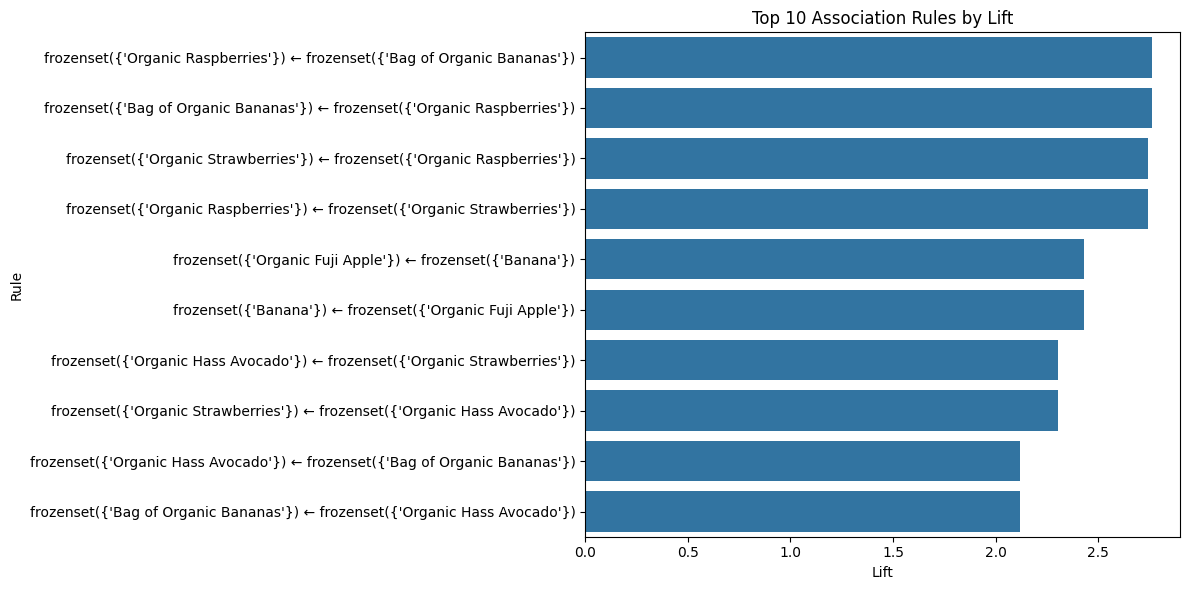

In [34]:
plt.figure(figsize=(12, 6))
sns.barplot(x=top_rules['lift'], y=top_rules['consequents'].astype(str) + ' ← ' + top_rules['antecedents'].astype(str))
plt.title('Top 10 Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Rule')
plt.tight_layout()
plt.show()


Network Graph of Top Product Associations

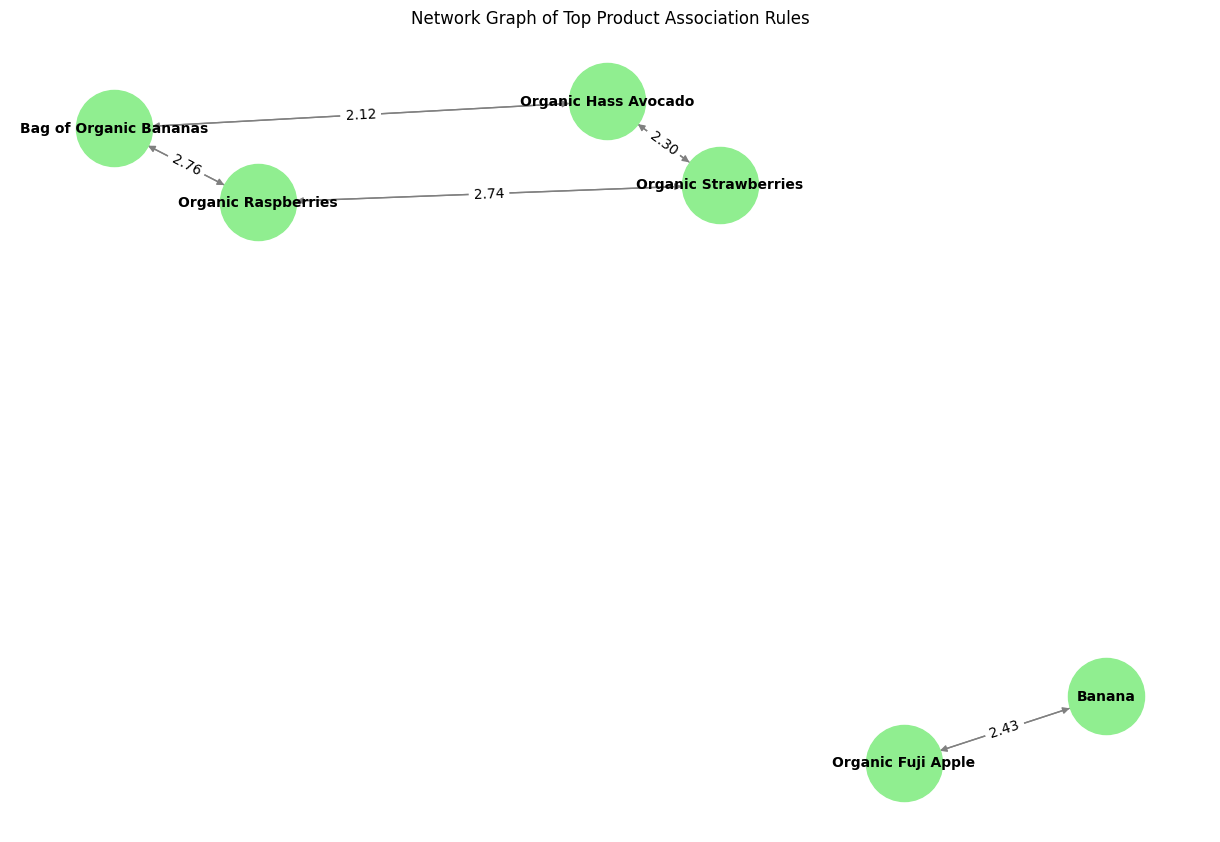

In [30]:
import networkx as nx
G = nx.DiGraph()

for _, row in top_rules.iterrows():
    G.add_edge(
        ', '.join(list(row['antecedents'])),
        ', '.join(list(row['consequents'])),
        weight=row['lift']
    )

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.5)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightgreen', font_size=10, font_weight='bold', edge_color='gray', arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels={k: f"{v:.2f}" for k, v in edge_labels.items()})
plt.title('Network Graph of Top Product Association Rules')
plt.show()


## Rule-Based Recommendation Function

In [31]:
def recommend_products(selected_product, rules_df, top_n=5):
    # Convert sets to strings for easy comparison
    rules_df['antecedents_str'] = rules_df['antecedents'].apply(lambda x: next(iter(x)) if isinstance(x, frozenset) else str(x))

    # Filter rules where selected product is in the antecedents
    matching_rules = rules_df[rules_df['antecedents_str'] == selected_product]

    if matching_rules.empty:
        return f"No recommendations found for '{selected_product}'."

    # Sort by lift and get top_n
    recommendations = matching_rules.sort_values(by='lift', ascending=False).head(top_n)
    return recommendations[['antecedents', 'consequents', 'support', 'confidence', 'lift']]


### Calling my function

In [35]:
recommend_products("Organic Raspberries", filtered_rules)


,antecedents,consequents,support,confidence,lift
5,(Organic Raspberries),(Bag of Organic Bananas),0.0146,0.320175,2.760133
29,(Organic Raspberries),(Organic Strawberries),0.0108,0.236842,2.741228


In [36]:
!pip install streamlit pyngrok --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 54.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.4 MB/s eta 0:00:00


In [37]:
%%writefile app.py
import streamlit as st


st.title("🛒 Cross-Sell Product Recommender")

st.markdown("""
Welcome to the **Apriori-based Recommender**.
Type a product name to discover which items are commonly purchased with it.
""")

# Load the saved rules DataFrame
@st.cache_data
def load_rules():
    return pd.read_pickle("filtered_rules.pkl")  # Replace with the correct path if needed

rules_df = load_rules()

# Convert sets to string for easier filtering
rules_df['antecedents_str'] = rules_df['antecedents'].apply(lambda x: next(iter(x)) if isinstance(x, frozenset) else str(x))

# Sidebar search input
selected_product = st.selectbox("Choose a product to get recommendations:",
                                sorted(rules_df['antecedents_str'].unique()))

# Recommend function
def recommend_products(product, rules_df, top_n=5):
    matching = rules_df[rules_df['antecedents_str'] == product]
    if matching.empty:
        return None
    return matching.sort_values(by='lift', ascending=False).head(top_n)

# Display recommendations
st.subheader(f"📦 Recommendations for: **{selected_product}**")
recommendations = recommend_products(selected_product, rules_df)

if recommendations is not None:
    st.dataframe(recommendations[['consequents', 'support', 'confidence', 'lift']])
else:
    st.warning("No recommendations found.")


Writing app.py


In [38]:
filtered_rules.to_pickle("filtered_rules.pkl")


In [42]:
# Kill any running ngrok tunnel
from pyngrok import ngrok
ngrok.kill()


In [69]:
%%writefile app.py
import streamlit as st

st.title("🦜 Streamlit + Ngrok")
st.write("This is a public Streamlit app served via ngrok!")


Overwriting app.py


In [40]:
# Run Streamlit app in background
!streamlit run app.py --server.port 8501 > /dev/null 2>&1 &


In [41]:
from pyngrok import ngrok

# Connect to localhost:8501
public_url = ngrok.connect(8501, "http")
print("🔗 Public URL:", public_url)


ERROR:pyngrok.process.ngrok:t=2025-06-07T11:29:08+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-06-07T11:29:08+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2025-06-07T11:29:08+0000 lvl=eror msg="terminating with error" obj=app err="authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your aut

PyngrokNgrokError: The ngrok process errored on start: authentication failed: Usage of ngrok requires a verified account and authtoken.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nInstall your authtoken: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [43]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.title("🛒 Cross-Sell Product Recommender By Endurance Ogashi")

st.markdown("""
Welcome to the **Apriori-based Recommender**.
Type a product name to discover which items are commonly purchased with it.
""")

# Load the saved rules DataFrame
@st.cache_data
def load_rules():
    return pd.read_pickle("filtered_rules.pkl")  # Replace with the correct path if needed

rules_df = load_rules()

# Convert sets to string for easier filtering
rules_df['antecedents_str'] = rules_df['antecedents'].apply(lambda x: next(iter(x)) if isinstance(x, frozenset) else str(x))

# Sidebar search input
selected_product = st.selectbox("Choose a product to get recommendations:",
                                sorted(rules_df['antecedents_str'].unique()))

# Recommend function
def recommend_products(product, rules_df, top_n=5):
    matching = rules_df[rules_df['antecedents_str'] == product]
    if matching.empty:
        return None
    return matching.sort_values(by='lift', ascending=False).head(top_n)

# Display recommendations
st.subheader(f"📦 Recommendations for: **{selected_product}**")
recommendations = recommend_products(selected_product, rules_df)

if recommendations is not None:
    st.dataframe(recommendations[['consequents', 'support', 'confidence', 'lift']])
else:
    st.warning("No recommendations found.")


Overwriting app.py


In [44]:
filtered_rules.to_pickle("filtered_rules.pkl")


In [45]:
from pyngrok import ngrok

# Replace with your actual token
!ngrok config add-authtoken 2y8cS2d9my8oLnYwIaPjpOXGxcf_2WeNfvmizeBu96ghv3PVU


Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
from pyngrok import ngrok

# Kill existing tunnel if running
ngrok.kill()

# Create a new tunnel to the Streamlit app
public_url = ngrok.connect(8501, "http")
print("🔗 Public URL:", public_url)

# Launch the app
!streamlit run app.py &


🔗 Public URL: NgrokTunnel: "https://a997-34-148-139-203.ngrok-free.app" -> "http://localhost:8501"



  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.148.139.203:8502

